# R14. Is the bias correction of the population w_GS estimate valid under the alternative explanations?

R13 calibrated the hierarchical estimator on cohorts in which the only true change was in w_GS, under the assumed
fixed constants (E[μ̂] = −0.071 + 0.795 μ, giving ×0.76 [0.72, 0.82] for the data). The reviewer asks whether the
correction holds when the true effect also involves input noise, when only noise changes, or when the fixed
constants are misspecified. Cohorts have the data's structure (36 in-reach hemispheres, 19 patients, OFF states
from the patients' posteriors, patient effects τ = 0.09, hemisphere effects 0.05, session nuisance as in training).

| design | true change | answers |
|---|---|---|
| noise only (moderate) | Δlog₁₀σ = −U(0.02, 0.20) per hemisphere, w_GS unchanged | how low the w_GS estimate goes when only noise changes |
| noise only (strong) | Δlog₁₀σ = −U(0.15, 0.25) | the same for the largest simulated noise reductions |
| w_GS + noise | w_GS ×0.9 / ×0.8 / ×0.7 and Δlog₁₀σ = −U(0.02, 0.20) | calibration line when noise also changes |
| w_GG ×0.5 | w_GS ×1.0 / ×0.8, misspecified constant | calibration line with weaker GPe self-inhibition |
| BG delays ×1.25 | w_GS ×1.0 / ×0.8, misspecified constants | calibration line with longer loop delays |

For each calibration family the data's estimate is converted into a bias-corrected change with a Neyman-belt 90%
interval, and compared with the R13 (w_GS-only, assumed constants) calibration. Every design is saved after it is
simulated and the notebook resumes if re-run. Runtime ≈ pipeline load + 2.5–3 h.

## 0. Settings

In [1]:
from pathlib import Path

REV_SCRIPT = Path(r"revision_analyses.py")    # ← round-1 script (the version with RUN_ONLY), same folder
PIPELINE = r"pd_pac_v51_circuit.py"
DS_ROOT = r"<local path>"                 # ← your ds004998 path
OUT_DIR = r"pd_pac_v4_outputs"                # ← same output folder (caches, R13 results)
GPU_ID = 1
QUICK = False

NOISE_MOD, NOISE_STRONG = (0.02, 0.20), (0.15, 0.25)
# (label, family, w_GS factor, noise range or None, misspecification key or None, cohorts)
DESIGN = [("noise only (moderate)", "w_GS + noise", 1.00, NOISE_MOD, None, 24),
          ("noise only (strong)", "noise only (strong)", 1.00, NOISE_STRONG, None, 16),
          ("×0.90 + noise", "w_GS + noise", 0.90, NOISE_MOD, None, 16),
          ("×0.80 + noise", "w_GS + noise", 0.80, NOISE_MOD, None, 16),
          ("×0.70 + noise", "w_GS + noise", 0.70, NOISE_MOD, None, 16),
          ("w_GG ×0.5, ×1.00", "w_GG ×0.5", 1.00, None, "w_GG ×0.5", 16),
          ("w_GG ×0.5, ×0.80", "w_GG ×0.5", 0.80, None, "w_GG ×0.5", 16),
          ("BG delays ×1.25, ×1.00", "BG delays ×1.25", 1.00, None, "BG delays ×1.25", 16),
          ("BG delays ×1.25, ×0.80", "BG delays ×1.25", 0.80, None, "BG delays ×1.25", 16)]
COHORT_SCALE = 1.0
TAU_TRUE, SIGMA_TRUE = 0.09, 0.05
SEED5 = 20261124

## 1. Load the frozen pipeline and helper functions

In [ ]:
import re

src = REV_SCRIPT.read_text(encoding="utf-8")
OVR = {"PIPELINE": f"Path(r\"{PIPELINE}\")", "DS_ROOT": f"r\"{DS_ROOT}\"", "OUT_DIR": f"r\"{OUT_DIR}\"", "GPU_ID": str(GPU_ID),
       "QUICK": str(QUICK), "RUN_OXFORD_REV": "False", "RUN_ONLY": "set()"}
for name, value in OVR.items():
    line = f"{name} = {value}"
    src, n = re.subn(rf"^{name}\s*=.*$", lambda _m, line=line: line, src, count=1, flags=re.M)
    assert n == 1, f"could not find the setting {name} in {REV_SCRIPT}"
exec(compile(src, str(REV_SCRIPT), "exec"), globals())
RUN_ONLY = None

In [3]:
from statsmodels.stats.proportion import proportion_confint

KEYS36 = [k for k in FS_DS if k in JS_DS]
SUBJ = np.array([k[0] for k in KEYS36]); SUBS = pd.unique(SUBJ)
KG = JP.index("w_GS"); KN = JP.index("log10_sig"); G0 = len(JP); WG = J_W[KG]
R13 = REV / "R13"; R14 = REV / "R14"; R14.mkdir(exist_ok=True)
wilson = lambda k, n: proportion_confint(k, n, alpha=0.05, method="wilson")

Ds_dat = [JS_DS[k][:, G0 + KG] for k in KEYS36]; mv_dat = np.array([flat_likelihood(d, WG) for d in Ds_dat])
H_DAT, _ = hierarchical_normal(mv_dat[:, 0], mv_dat[:, 1], SUBJ, WG); EST = H_DAT["mu_med"]
print(f"{len(KEYS36)} hemispheres, {len(SUBS)} patients; data hierarchical estimate ×{np.exp(EST):.3f}")


def off_draw(rng, k):
    s_ = FS_DS[k]
    return np.clip(s_[rng.integers(0, len(s_), 1), :nP], PRIOR_LO, PRIOR_HI)

36 hemispheres, 19 patients; data hierarchical estimate ×0.746


## 2. Simulate the designs

In [4]:
def R14_simulate():
    base_c = dict(CIRC)
    for di, (lab, fam, fac, nr, ms, nco) in enumerate(DESIGN):
        f = R14 / f"design_{di}.csv"
        if f.exists():
            print(f"[{lab}] loaded"); continue
        n_c = max(2, int(round(nco * COHORT_SCALE))); rng = np.random.default_rng(SEED5 + 1000 * di)
        TO, TN, meta = [], [], []
        for c in range(n_c):
            u = dict(zip(SUBS, TAU_TRUE * rng.standard_normal(len(SUBS))))
            for h, k in enumerate(KEYS36):
                d = float(np.clip(np.log(fac) + u[k[0]] + SIGMA_TRUE * rng.standard_normal(), -0.95 * WG, 0.95 * WG)) if fac != 1.0 \
                    else float(np.clip(u[k[0]] + SIGMA_TRUE * rng.standard_normal(), -0.95 * WG, 0.95 * WG))
                th = off_draw(rng, k); Dm = np.zeros((1, nM)); Dm[0, KG] = d
                dn = -rng.uniform(*nr) if nr is not None else 0.0
                Dm[0, KN] = dn
                TO.append(th); TN.append(apply_full(th, Dm, nuisance_draw(th, rng))); meta.append((c, h, d, dn))
        TO, TN = np.concatenate(TO), np.concatenate(TN)
        try:
            for kk, v in (MISSPEC[ms].items() if ms else []):
                CIRC[kk] = base_c[kk] * v
            print(f"[{lab}] simulating {n_c} cohorts ({len(TO)} pairs)")
            S = simulate_stats(np.concatenate([TO, TN]), SEED5 + 10 + di)
        finally:
            CIRC.clear(); CIRC.update(base_c)
        F = pair_features(S[:len(TO)], S[len(TO):]); ok = np.isfinite(F).all(1)
        D = [joint_samples(JPOST, F[i], 2000)[:, G0:] if ok[i] else None for i in range(len(F))]
        rows = []
        for c in range(n_c):
            idx = [i for i, m in enumerate(meta) if m[0] == c and D[i] is not None]
            Ds = [D[i][:, KG] for i in idx]; subj = SUBJ[[meta[i][1] for i in idx]]
            r_ = np.random.default_rng(c); G = np.mean([d[r_.integers(0, len(d), 4000)] for d in Ds], 0)
            mv = np.array([flat_likelihood(d, WG) for d in Ds]); h, _ = hierarchical_normal(mv[:, 0], mv[:, 1], subj, WG)
            rows.append(dict(design=lab, family=fam, factor=fac, misspec=ms or "assumed", noise=str(nr), cohort=c, true_mu=np.log(fac),
                             true_sample_mean=np.mean([meta[i][2] for i in idx]), mean_dnoise=np.mean([meta[i][3] for i in idx]),
                             post_dnoise=np.mean([D[i][:, KN].mean() for i in idx]),
                             sparse_est=np.median(G), sparse_P=(G < 0).mean(),
                             hier_est=h["mu_med"], hier_lo=h["mu_lo"], hier_hi=h["mu_hi"], hier_P=h["P_mu_neg"]))
        pd.DataFrame(rows).to_csv(f, index=False)


run(R14_simulate)

[noise only (moderate)] loaded
[noise only (strong)] loaded
[×0.90 + noise] simulating 16 cohorts (576 pairs)
  1152 sims: 100.0%  (  225 s)
    statistics: 181 s
[×0.80 + noise] simulating 16 cohorts (576 pairs)
  1152 sims: 100.0%  (  224 s)
    statistics: 196 s
[×0.70 + noise] simulating 16 cohorts (576 pairs)
  1152 sims: 100.0%  (  226 s)
    statistics: 178 s
[w_GG ×0.5, ×1.00] simulating 16 cohorts (576 pairs)
  1152 sims: 100.0%  (  224 s)
    statistics: 197 s
[w_GG ×0.5, ×0.80] simulating 16 cohorts (576 pairs)
  1152 sims: 100.0%  (  224 s)
    statistics: 204 s
[BG delays ×1.25, ×1.00] simulating 16 cohorts (576 pairs)
  1152 sims: 100.0%  (  231 s)
    statistics: 201 s
[BG delays ×1.25, ×0.80] simulating 16 cohorts (576 pairs)
  1152 sims: 100.0%  (  321 s)
    statistics: 189 s
[R14_simulate: 105.5 min]


## 3. Calibration under each alternative, and the corrected population change

Hierarchical w_GS estimator under alternative true effects (data estimate ×0.746; log-scale bias ± s.e.;
cohorts_le_data / z_data: how often, and how far, a cohort's estimate reaches the data's)
                design  n  true  hier_mean   bias  bias_se    sd  cov90     cov90_ci   P95       P95_ci cohorts_le_data  z_data  sparse_mean  post_dnoise  true_dnoise
 noise only (moderate) 24   1.0      0.877 -0.131    0.011 0.053  0.250 (0.12, 0.45) 0.750 (0.55, 0.88)            0/24  -3.068        0.929       -0.033       -0.110
   noise only (strong) 16   1.0      0.850 -0.163    0.013 0.051  0.188 (0.07, 0.43) 0.812 (0.57, 0.93)            0/16  -2.525        0.911       -0.046       -0.202
         ×0.90 + noise 16   0.9      0.792 -0.128    0.011 0.044  0.250  (0.1, 0.49) 1.000  (0.81, 1.0)            2/16  -1.345        0.890       -0.031       -0.110
         ×0.80 + noise 16   0.8      0.728 -0.094    0.008 0.033  0.562 (0.33, 0.77) 1.000  (0.81, 1.0)           13/16   0.766        0.

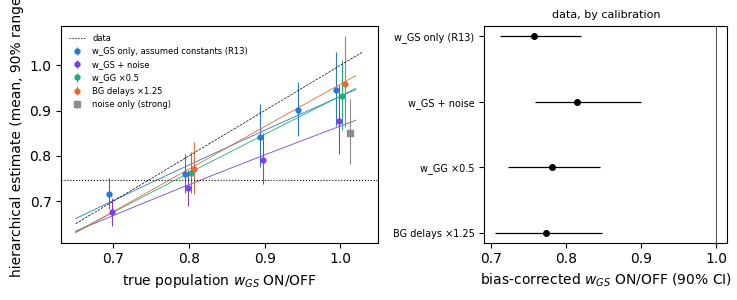

[R14_summarise: 0.0 min]


In [5]:
def belt(df, est, grid=np.linspace(np.log(0.5), np.log(1.1), 1201)):
    """Linear calibration E[μ̂] = a + bμ and Neyman-belt 90% interval for μ given an observed estimate."""
    mus = np.sort(df.true_mu.unique())
    m = np.array([df[df.true_mu == u].hier_est.mean() for u in mus]); s = np.array([df[df.true_mu == u].hier_est.std(ddof=1) for u in mus])
    b, a = np.polyfit(mus, m, 1)
    if len(mus) > 2:
        s1, s0 = np.polyfit(mus, s, 1)
    else:
        s1, s0 = 0.0, s.mean()
    mg, sg = a + b * grid, np.maximum(s0 + s1 * grid, 1e-3)
    inside = np.abs(est - mg) <= 1.645 * sg
    return dict(a=a, b=b, point=(est - a) / b, lo=grid[inside].min() if inside.any() else np.nan,
                hi=grid[inside].max() if inside.any() else np.nan)


def R14_summarise():
    T = pd.concat([pd.read_csv(R14 / f"design_{di}.csv") for di in range(len(DESIGN)) if (R14 / f"design_{di}.csv").exists()])
    T.to_csv(R14 / "cohorts_all.csv", index=False)
    rows = []
    for lab, g in T.groupby("design", sort=False):
        n = len(g); cov = int(((g.hier_lo <= g.true_mu) & (g.true_mu <= g.hier_hi)).sum()); fp = int((g.hier_P > .95).sum())
        k = int((g.hier_est <= EST).sum())
        rows.append(dict(design=lab, n=n, true=np.exp(g.true_mu.iloc[0]), hier_mean=np.exp(g.hier_est.mean()),
                         bias=(g.hier_est - g.true_mu).mean(), bias_se=(g.hier_est - g.true_mu).std(ddof=1) / np.sqrt(n),
                         sd=g.hier_est.std(ddof=1), cov90=cov / n, cov90_ci=tuple(np.round(wilson(cov, n), 2)),
                         P95=fp / n, P95_ci=tuple(np.round(wilson(fp, n), 2)),
                         cohorts_le_data=f"{k}/{n}", z_data=(EST - g.hier_est.mean()) / g.hier_est.std(ddof=1),
                         sparse_mean=np.exp(g.sparse_est.mean()), post_dnoise=g.post_dnoise.mean(), true_dnoise=g.mean_dnoise.mean()))
    S_ = pd.DataFrame(rows)
    print(f"Hierarchical w_GS estimator under alternative true effects (data estimate ×{np.exp(EST):.3f}; log-scale bias ± s.e.;\n"
          "cohorts_le_data / z_data: how often, and how far, a cohort's estimate reaches the data's)")
    print(S_.round(3).to_string(index=False)); S_.to_csv(R14 / "summary.csv", index=False); SUMMARY["R14"] = S_

    # calibration families
    fams = {}
    if (R13 / "C_cohorts_all.csv").exists():
        C = pd.read_csv(R13 / "C_cohorts_all.csv"); fams["w_GS only, assumed constants (R13)"] = C[(C.dist == "normal") & (C.tau_true == 0.09)]
    for fam in ("w_GS + noise", "w_GG ×0.5", "BG delays ×1.25"):
        g = T[T.family == fam]
        if g.true_mu.nunique() >= 2:
            fams[fam] = g
    out = []
    for fam, g in fams.items():
        r = belt(g, EST)
        out.append(dict(calibration=fam, n_cohorts=len(g), a=r["a"], b=r["b"], corrected=np.exp(r["point"]),
                        neyman_lo90=np.exp(r["lo"]), neyman_hi90=np.exp(r["hi"])))
    O = pd.DataFrame(out)
    print("\nBias-corrected population w_GS change of the data under each calibration (E[μ̂] = a + b·μ; Neyman-belt 90% interval):")
    print(O.round(3).to_string(index=False)); O.to_csv(R14 / "corrected_estimates.csv", index=False); SUMMARY["R14_corrected"] = O
    if len(O):
        print(f"\nrange of corrected estimates: ×{O.corrected.min():.3f}–×{O.corrected.max():.3f}; "
              f"envelope of the 90% intervals: ×{O.neyman_lo90.min():.3f}–×{O.neyman_hi90.max():.3f}")
    nz = S_[S_.design.str.startswith("noise only")]
    for r in nz.itertuples():
        print(f"{r.design}: hierarchical w_GS estimate ×{r.hier_mean:.3f} (s.d. {r.sd:.3f} log); {r.cohorts_le_data} cohorts reached the data's "
              f"estimate (z = {r.z_data:+.1f}); network's mean posterior Δlog10σ {r.post_dnoise:+.3f} (true {r.true_dnoise:+.3f})")

    # figure
    cols = {"w_GS only, assumed constants (R13)": "#2a78d6", "w_GS + noise": "#7b3fe4", "w_GG ×0.5": "#1baf7a", "BG delays ×1.25": "#eb6834"}
    fig, axs = plt.subplots(1, 2, figsize=(7.48, 3.1), gridspec_kw=dict(width_ratios=[1.3, 1]))
    xx = np.linspace(np.log(.65), 0.02, 50)
    for j, (fam, g) in enumerate(fams.items()):
        m = g.groupby("true_mu").hier_est.agg(["mean", "std"]); c = cols.get(fam, "k")
        axs[0].errorbar(np.exp(m.index) + (j - 1.5) * .004, np.exp(m["mean"]), yerr=[np.exp(m["mean"]) - np.exp(m["mean"] - 1.645 * m["std"]),
                        np.exp(m["mean"] + 1.645 * m["std"]) - np.exp(m["mean"])], fmt="o", ms=3.5, color=c, lw=.8, label=fam)
        r = O[O.calibration == fam].iloc[0]; axs[0].plot(np.exp(xx), np.exp(r.a + r.b * xx), color=c, lw=.6)
    if "noise only (strong)" in set(T.family):
        g = T[T.family == "noise only (strong)"]
        axs[0].errorbar([1.0 + .012], [np.exp(g.hier_est.mean())], yerr=[[np.exp(g.hier_est.mean()) - np.exp(g.hier_est.mean() - 1.645 * g.hier_est.std())],
                        [np.exp(g.hier_est.mean() + 1.645 * g.hier_est.std()) - np.exp(g.hier_est.mean())]], fmt="s", ms=4, color="#8c8c8c", lw=.8,
                        label="noise only (strong)")
    axs[0].axhline(np.exp(EST), color="k", ls=":", lw=.8, label="data")
    axs[0].plot([.65, 1.03], [.65, 1.03], "k--", lw=.5)
    axs[0].set_xlabel(r"true population $w_{GS}$ ON/OFF"); axs[0].set_ylabel("hierarchical estimate (mean, 90% range)")
    axs[0].legend(frameon=False, fontsize=6, loc="upper left")
    y = np.arange(len(O))
    xe = np.nan_to_num(np.clip(np.vstack([O.corrected - O.neyman_lo90, O.neyman_hi90 - O.corrected]), 0, None))
    axs[1].errorbar(O.corrected, y, xerr=xe, fmt="o", color="k", ms=4, lw=.9)
    axs[1].set_yticks(y, [c.replace(", assumed constants (R13)", " (R13)") for c in O.calibration], fontsize=7)
    axs[1].axvline(1, color="k", lw=.5); axs[1].set_xlabel(r"bias-corrected $w_{GS}$ ON/OFF (90% CI)"); axs[1].invert_yaxis()
    axs[1].set_title("data, by calibration", fontsize=8)
    fig.tight_layout(); fig.savefig(REVF / "R14_calibration_alternatives.png", dpi=300); plt.show()


run(R14_summarise)